In [18]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import Lasso
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from tqdm import tqdm

In [19]:
def get_x_y(periods):
    X, y = [], []
    for tp in tqdm(periods):
        irradiance_measurements = [float(item['irradiance']) for item in tp['history']]
        target_irradiance = float(tp['target_irradiance'])
        X.append(irradiance_measurements)
        y.append(target_irradiance)
        
    return np.array(X), np.array(y)

### Train Lasso model

In [20]:
folsom_periods_path = Path('../data/periods_30m.pickle')

with open(folsom_periods_path, 'rb') as f:
    periods = pickle.load(f)

test_periods = list(filter(lambda p: p['history'][-1]['image_name'].startswith('2016'), periods))
train_val_periods = list(filter(lambda p: not p['history'][-1]['image_name'].startswith('2016'), periods))

# number of days for validatation dataset to get 80-20 ratio of train-val datasets
val_size = 146
np.random.seed(42)
val_dates = [
    str(y) + str(m).zfill(2) + str(d).zfill(2) for y, m, d in zip(
        np.random.randint(2014, 2016, size=val_size),
        np.random.randint(1, 13, size=val_size),
        np.random.randint(1, 29, size=val_size),
)]
val_periods = list(filter(lambda p: p['history'][-1]['image_name'][:8] in val_dates, train_val_periods))
train_periods = list(filter(lambda p: p['history'][-1]['image_name'][:8] not in val_dates, train_val_periods))

print(f'Train size: {len(train_periods)}')
print(f'Validation size: {len(val_periods)}')
print(f'Test size: {len(test_periods)}')

Train size: 379047
Validation size: 84169
Test size: 240788


In [21]:
X_train, y_train = get_x_y(train_periods)
X_val, y_val = get_x_y(val_periods)
X_test, y_test = get_x_y(test_periods)

100%|██████████| 240788/240788 [00:00<00:00, 2714901.89it/s]


In [22]:
model = Lasso(random_state=42)

model.fit(X_train, y_train)
model.score(X_train, y_train), model.score(X_val, y_val), model.score(X_test, y_test)

(0.8419009070249878, 0.8638077677646766, 0.8546992527093485)

### Evaluate

In [32]:
forecast_length = 30

# eval_periods_path = Path(f'../data/Prepared/periods_{forecast_length}m.pickle')
# eval_periods_path = Path(f'../data/Modena/modena_periods_4_5_{forecast_length}.pkl')
# eval_periods_path = Path(f'../data/Poznan/poznan_periods_4_5_{forecast_length}.pkl')
eval_periods_path = Path(f'../data/Karpicko/karpicko_periods_4_5_{forecast_length}.pkl')

with open(eval_periods_path, 'rb') as f:
    eval_periods = pickle.load(f)

X_eval, y_eval = get_x_y(eval_periods)
target_irradiances = np.stack(y_eval)
print(f'Test size: {len(eval_periods)}')

100%|██████████| 9301/9301 [00:00<00:00, 1138149.77it/s]

Test size: 9301


In [33]:
lasso_predictions = []
for _X in tqdm(X_eval):
    _X = np.array(_X).reshape(1, -1)
    pred = model.predict(_X)[0]
    lasso_predictions.append(float(pred))

100%|██████████| 9301/9301 [00:00<00:00, 51148.04it/s]


RMSE: 141.75769560933577
MAE: 76.53127273610252
MAPE: 6.127033409054308e+16


Text(0.5, 0, 'Time')

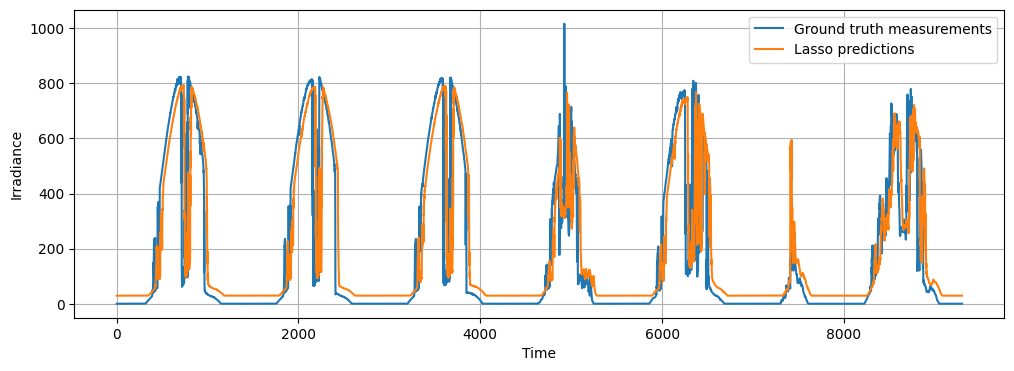

In [ ]:
rmse = root_mean_squared_error(y_true=target_irradiances, y_pred=np.array(lasso_predictions))
mae = mean_absolute_error(y_true=target_irradiances, y_pred=np.array(lasso_predictions))
mape = mean_absolute_percentage_error(y_true=target_irradiances, y_pred=np.array(lasso_predictions))

print(f'RMSE: {rmse}')
print(f'MAE: {mae}')
print(f'MAPE: {mape}')

fig = plt.figure(figsize=(12, 4))

plt.plot(target_irradiances)
plt.plot(lasso_predictions)
plt.legend(['Ground truth measurements', 'Lasso predictions'])
plt.grid(True)
plt.ylabel('Irradiance')
plt.xlabel('Time')